# Penerapan Algoritma XGBoost untuk Klasifikasi Perkembangan Sosial-Emosional Anak Usia Dini
**Penelitian Skripsi: RA Qotrunnada (Wafiqotissalamah - NIM: 22122013)**

---
> 📌 **PANDUAN STRUKTUR NOTEBOOK & METODOLOGI PENELITIAN:**
> Notebook ini mendokumentasikan 3 fase metodologis pengerjaan skripsi:
> 1. **Bagian I: Eksplorasi Awal & Baseline Prototipe (Stratified 5-Fold Cross-Validation)**  
>    Fase awal perancangan pipeline, transformasi fitur 8 indikator, validasi integritas data, dan pengujian model XGBoost awal menggunakan 5-Fold CV.
> 2. **Bagian II: Eksperimen Optimasi Jumlah Fold K (K = 2 hingga 14)**  
>    Pengujian empiris variasi nilai $ pada 110 data anak untuk menemukan jumlah partisi yang memberikan performa generalisasi terbaik. Hasil membuktikan **K = 12** menghasilkan performa tertinggi.
> 3. **Bagian III: Metodologi Definitif Skripsi BAB IV (Stratified 12-Fold CV OOF dengan 5 Random State)**  
>    Implementasi metode final: evaluasi stabilitas partisi dengan 5 random state ([2026, 42, 123, 2025, 20260926]) pada 12-Fold Out-of-Fold (OOF), perbandingan gain terhadap Baseline Dummy Classifier, analisis Confusion Matrix rerata 5 seed, dan pelatihan model final pada seluruh 110 data anak.

---

In [ ]:
# 1. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 20260926
TEST_SIZE = 0.20
N_SPLITS = 5

FEATURES = [f"X{i}" for i in range(1, 9)]
CLASS_NAMES = ["BB", "MB", "BSH", "BSB"]
TARGET_TO_XGB = {"BB": 0, "MB": 1, "BSH": 2, "BSB": 3}

XGB_PARAMS = {
    "n_estimators": 100,
    "max_depth": 4,
    "learning_rate": 0.1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": RANDOM_STATE,
    "objective": "multi:softprob",
    "num_class": 4,
    "eval_metric": "mlogloss"
}

print("Library dan parameter berhasil disiapkan.")


Library dan parameter berhasil disiapkan.


In [ ]:
# 2. Upload file Excel dan tampilkan SELURUH data
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

xl = pd.ExcelFile(file_name)
print("Sheet yang tersedia:", xl.sheet_names)

df = pd.read_excel(file_name, sheet_name="Data Anak")
print("Ukuran Data Anak:", df.shape)

# Tampilkan seluruh baris dan kolom, bukan hanya beberapa baris pertama.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(df)


Saving Data Penelitian RA Qotrunnada.xlsx to Data Penelitian RA Qotrunnada.xlsx
Sheet yang tersedia: ['Data Anak', 'Distribusi Target', '8 Indikator', 'Data Model', 'Persiapan Model']
Ukuran Data Anak: (110, 13)


,No,Nama,Kelas,Umur,X1,X2,X3,X4,X5,X6,X7,X8,Target
0,1,Azzam,Kelas B Putra Al Qomar,"6,2",2,1,2,1,1,1,2,3,BB
1,2,Fathir,Kelas B Putra Al Qomar,"5,1",4,3,4,3,4,3,3,4,BSB
2,3,Albirru,Kelas B Putra Al Qomar,"5,8",1,1,1,1,1,3,2,3,BB
3,4,Attar,Kelas B Putra Al Qomar,"5,10",4,4,2,4,4,2,2,1,BSH
4,5,Biru,Kelas B Putra Al Qomar,"5,10",2,1,4,1,2,3,1,2,MB
5,6,Abid,Kelas B Putra Al Qomar,"5,8",1,1,2,2,2,1,1,1,BB
6,7,Faris,Kelas B Putra Al Qomar,"6,2",3,3,4,4,4,4,2,3,BSB
7,8,Gezha,Kelas B Putra Al Qomar,"6,2",2,3,2,2,3,1,3,3,MB
8,9,Mas Ghafi,Kelas B Putra Al Qomar,"5,4",1,1,4,3,4,1,4,1,MB
9,10,Adek Ghazi,Kelas B Putra Al Qomar,"5,1",2,4,4,4,4,3,1,4,BSB


In [ ]:
# 3. Pemeriksaan awal
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("\nNama kolom:")
print(df.columns.tolist())

print("\nNilai kosong:")
display(df.isna().sum().to_frame("Jumlah Kosong"))

print("\nDistribusi Target:")
display(df["Target"].value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\nStatistik skor X1-X8:")
display(df[FEATURES].describe())


Jumlah baris: 110
Jumlah kolom: 13

Nama kolom:
['No', 'Nama', 'Kelas', 'Umur', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Target']

Nilai kosong:


,Jumlah Kosong
No,0
Nama,0
Kelas,0
Umur,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0



Distribusi Target:


,count
Target,
BB,30
MB,14
BSH,39
BSB,27



Statistik skor X1-X8:


,X1,X2,X3,X4,X5,X6,X7,X8
count,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000,110.000000
mean,2.436364,2.436364,2.536364,2.572727,2.490909,2.618182,2.509091,2.363636
std,1.153592,1.215551,1.186138,1.199840,1.186665,1.196185,1.163240,1.178767
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.250000,1.000000
50%,2.000000,2.500000,3.000000,3.000000,2.000000,3.000000,2.000000,2.000000
75%,3.750000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000
max,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000


In [ ]:
# 4. Validasi dan normalisasi
df_clean = df.copy()
df_clean.columns = [str(c).strip() for c in df_clean.columns]

missing_cols = [c for c in FEATURES + ["Target"] if c not in df_clean.columns]
assert not missing_cols, f"Kolom wajib belum tersedia: {missing_cols}"

# Cek missing value
missing_total = int(df_clean[FEATURES + ["Target"]].isna().sum().sum())
print("Total nilai kosong pada fitur + target:", missing_total)

# Konversi skor menjadi numerik/integer setelah lolos pemeriksaan
for col in FEATURES:
    numeric = pd.to_numeric(df_clean[col], errors="coerce")
    assert numeric.notna().all(), f"Ada nilai non-numerik pada {col}"
    assert (numeric >= 1).all() and (numeric <= 4).all(), f"Nilai {col} di luar rentang 1-4"
    assert np.all(numeric == numeric.round()), f"Nilai {col} mengandung desimal"
    df_clean[col] = numeric.astype(int)

# Normalisasi target
df_clean["Target"] = df_clean["Target"].astype(str).str.strip().str.upper()
assert df_clean["Target"].isin(CLASS_NAMES).all(), "Ada label target yang tidak valid."

print("Validasi data selesai.")
print("Ukuran data setelah validasi:", df_clean.shape)


Total nilai kosong pada fitur + target: 0
Validasi data selesai.
Ukuran data setelah validasi: (110, 13)


In [ ]:
# 5. Cek konsistensi target terhadap aturan total skor
def rule_target(scores):
    total = int(sum(scores))
    if 8 <= total <= 13:
        return "BB"
    elif 14 <= total <= 19:
        return "MB"
    elif 20 <= total <= 25:
        return "BSH"
    elif 26 <= total <= 32:
        return "BSB"
    return "INVALID"

df_clean["Total_Skor"] = df_clean[FEATURES].sum(axis=1)
df_clean["Target_Aturan"] = df_clean[FEATURES].apply(lambda r: rule_target(r.tolist()), axis=1)

mismatch = int((df_clean["Target"] != df_clean["Target_Aturan"]).sum())

print("Jumlah target tidak sesuai aturan:", mismatch)
display(pd.crosstab(df_clean["Target"], df_clean["Target_Aturan"]))


Jumlah target tidak sesuai aturan: 0


Target_Aturan,BB,BSB,BSH,MB
Target,,,,
BB,30,0,0,0
BSB,0,27,0,0
BSH,0,0,39,0
MB,0,0,0,14


In [ ]:
# 6. Transformasi target
df_clean["Target_XGBoost"] = df_clean["Target"].map(TARGET_TO_XGB).astype(int)

X = df_clean[FEATURES].copy()
y = df_clean["Target_XGBoost"].copy()

print("Fitur:", FEATURES)
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)


Fitur: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
Ukuran X: (110, 8)
Ukuran y: (110,)


In [ ]:
# 7. Menyiapkan Stratified 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(f"Jumlah data: {len(X)}")
print(f"Jumlah fold: {N_SPLITS}")
print(f"Perkiraan data validasi per fold: {len(X) // N_SPLITS}–{int(np.ceil(len(X) / N_SPLITS))}")


Jumlah data: 110
Jumlah fold: 5
Perkiraan data validasi per fold: 22–22


In [ ]:
# 8. Evaluasi XGBoost pada setiap fold
cv_results = []
oof_pred = np.full(shape=len(y), fill_value=-1, dtype=int)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    model_cv = xgb.XGBClassifier(**XGB_PARAMS)
    model_cv.fit(X_tr, y_tr)
    pred_val = model_cv.predict(X_val)
    oof_pred[val_idx] = pred_val

    cv_results.append({
        "Fold": fold,
        "Sampel Latih": len(tr_idx),
        "Sampel Validasi": len(val_idx),
        "Accuracy": accuracy_score(y_val, pred_val),
        "Macro Precision": precision_score(y_val, pred_val, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_val, pred_val, average="macro", zero_division=0),
        "Macro F1": f1_score(y_val, pred_val, average="macro", zero_division=0)
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.style.format({
    "Accuracy": "{:.2%}",
    "Macro Precision": "{:.2%}",
    "Macro Recall": "{:.2%}",
    "Macro F1": "{:.2%}"
}))

print("Rata-rata hasil 5-fold:")
display(cv_df[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]].mean().to_frame("Mean"))

print("Standar deviasi antar-fold:")
display(cv_df[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]].std().to_frame("Std"))


,Fold,Sampel Latih,Sampel Validasi,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1,88,22,72.73%,60.42%,60.42%,60.42%
1,2,88,22,72.73%,55.42%,63.10%,58.18%
2,3,88,22,68.18%,64.55%,67.71%,63.85%
3,4,88,22,68.18%,52.29%,62.50%,54.62%
4,5,88,22,59.09%,59.72%,55.62%,56.68%


Rata-rata hasil 5-fold:


,Mean
Accuracy,0.681818
Macro Precision,0.584802
Macro Recall,0.618690
Macro F1,0.587471


Standar deviasi antar-fold:


,Std
Accuracy,0.055670
Macro Precision,0.047398
Macro Recall,0.043902
Macro F1,0.035521


In [ ]:
# 9. Evaluasi out-of-fold dan baseline sederhana

baseline = DummyClassifier(strategy="most_frequent")
baseline_oof_pred = cross_val_predict(
    baseline, X, y, cv=skf, method="predict"
)

def metric_row(name, y_true, y_hat):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_hat),
        "Macro Precision": precision_score(y_true, y_hat, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_hat, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_hat, average="macro", zero_division=0)
    }

comparison_df = pd.DataFrame([
    metric_row("Baseline (kelas mayoritas)", y, baseline_oof_pred),
    metric_row("XGBoost (Stratified 5-Fold OOF)", y, oof_pred)
])
display(comparison_df.style.format({
    "Accuracy": "{:.2%}",
    "Macro Precision": "{:.2%}",
    "Macro Recall": "{:.2%}",
    "Macro F1": "{:.2%}"
}))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Baseline (kelas mayoritas),35.45%,8.86%,25.00%,13.09%
1,XGBoost (Stratified 5-Fold OOF),68.18%,60.24%,61.83%,60.08%


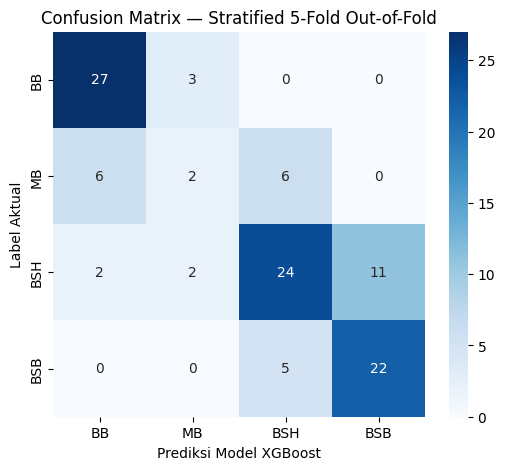

              precision    recall  f1-score   support

          BB       0.77      0.90      0.83        30
          MB       0.29      0.14      0.19        14
         BSH       0.69      0.62      0.65        39
         BSB       0.67      0.81      0.73        27

    accuracy                           0.68       110
   macro avg       0.60      0.62      0.60       110
weighted avg       0.65      0.68      0.66       110



In [ ]:
# 10. Confusion matrix dan classification report (prediksi out-of-fold)
cm = confusion_matrix(y, oof_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Prediksi Model XGBoost")
plt.ylabel("Label Aktual")
plt.title("Confusion Matrix — Stratified 5-Fold Out-of-Fold")
plt.show()

print(classification_report(
    y, oof_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0
))


,Indikator,Gain
3,X4,0.742617
1,X2,0.663889
5,X6,0.624737
4,X5,0.541134
2,X3,0.495730
7,X8,0.477063
0,X1,0.436856
6,X7,0.359022


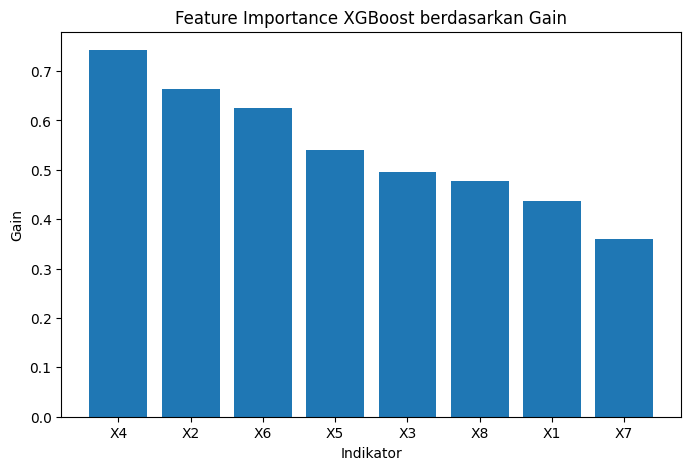

In [ ]:
# 11. Latih model final menggunakan seluruh data untuk kebutuhan implementasi

final_model = xgb.XGBClassifier(**XGB_PARAMS)
final_model.fit(X, y)

booster = final_model.get_booster()
gain_scores = booster.get_score(importance_type="gain")
importance_df = pd.DataFrame({
    "Indikator": FEATURES,
    "Gain": [float(gain_scores.get(f, 0.0)) for f in FEATURES]
}).sort_values("Gain", ascending=False)

display(importance_df)

plt.figure(figsize=(8, 5))
plt.bar(importance_df["Indikator"], importance_df["Gain"])
plt.xlabel("Indikator")
plt.ylabel("Gain")
plt.title("Feature Importance XGBoost berdasarkan Gain")
plt.show()


In [ ]:
# 12. Ringkasan hasil eksperimen
summary = pd.DataFrame({
    "Metrik": [
        "Jumlah data",
        "Jumlah fold",
        "Mean CV Accuracy",
        "Mean CV Macro Precision",
        "Mean CV Macro Recall",
        "Mean CV Macro F1",
        "Std CV Accuracy",
        "Std CV Macro F1",
        "Baseline OOF Accuracy",
        "Baseline OOF Macro F1"
    ],
    "Nilai": [
        len(df_clean),
        N_SPLITS,
        cv_df["Accuracy"].mean(),
        cv_df["Macro Precision"].mean(),
        cv_df["Macro Recall"].mean(),
        cv_df["Macro F1"].mean(),
        cv_df["Accuracy"].std(),
        cv_df["Macro F1"].std(),
        accuracy_score(y, baseline_oof_pred),
        f1_score(y, baseline_oof_pred, average="macro", zero_division=0)
    ]
})
display(summary)


,Metrik,Nilai
0,Jumlah data,110.000000
1,Jumlah fold,5.000000
2,Mean CV Accuracy,0.681818
3,Mean CV Macro Precision,0.584802
4,Mean CV Macro Recall,0.618690
5,Mean CV Macro F1,0.587471
6,Std CV Accuracy,0.055670
7,Std CV Macro F1,0.035521
8,Baseline OOF Accuracy,0.354545
9,Baseline OOF Macro F1,0.130872


---
# BAGIAN II: EKSPERIMEN OPTIMASI JUMLAH K-FOLD (K = 2 HINGGA 14)
*Eksperimen komparasi variasi nilai $ untuk menentukan jumlah fold cross-validation yang paling optimal bagi dataset 110 anak RA Qotrunnada.*
---

In [ ]:

# Pemeriksaan dataset untuk eksperimen K-Fold

print("Jumlah data:", len(X))
print("\nDistribusi kelas:")

print(
    y.map({
        0: "BB",
        1: "MB",
        2: "BSH",
        3: "BSB"
    }).value_counts().reindex(CLASS_NAMES, fill_value=0)
)

print("\nJumlah fitur:", X.shape[1])
print("Nama fitur:", list(X.columns))
print("Ada missing value:", X.isnull().sum().sum())


Jumlah data: 110

Distribusi kelas:
Target_XGBoost
BB     30
MB     14
BSH    39
BSB    27
Name: count, dtype: int64

Jumlah fitur: 8
Nama fitur: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
Ada missing value: 0


In [ ]:

# EKSPERIMEN PERBANDINGAN JUMLAH K-FOLD

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# Variasi jumlah fold yang akan diuji
FOLD_OPTIONS = list(range(2, 15))

# Menyimpan hasil setiap eksperimen
fold_comparison_results = []

for k in FOLD_OPTIONS:

    print(f"Sedang menjalankan {k}-Fold Cross Validation...")

    skf = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Menampung prediksi setiap data
    oof_predictions = np.full(len(y), -1, dtype=int)

    # Menyimpan skor evaluasi setiap fold
    fold_accuracy = []
    fold_precision = []
    fold_recall = []
    fold_f1 = []

    for train_idx, val_idx in skf.split(X, y):

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        model = XGBClassifier(**XGB_PARAMS)

        model.fit(X_train_fold, y_train_fold)

        y_pred = model.predict(X_val_fold).astype(int)

        oof_predictions[val_idx] = y_pred

        fold_accuracy.append(
            accuracy_score(y_val_fold, y_pred)
        )

        fold_precision.append(
            precision_score(
                y_val_fold, y_pred,
                average="macro",
                zero_division=0
            )
        )

        fold_recall.append(
            recall_score(
                y_val_fold, y_pred,
                average="macro",
                zero_division=0
            )
        )

        fold_f1.append(
            f1_score(
                y_val_fold, y_pred,
                average="macro",
                zero_division=0
            )
        )

    # Metrik keseluruhan dari gabungan OOF predictions
    overall_accuracy = accuracy_score(y, oof_predictions)

    overall_precision = precision_score(
        y, oof_predictions,
        average="macro",
        zero_division=0
    )

    overall_recall = recall_score(
        y, oof_predictions,
        average="macro",
        zero_division=0
    )

    overall_f1 = f1_score(
        y, oof_predictions,
        average="macro",
        zero_division=0
    )

    fold_comparison_results.append({
        "K-Fold": k,
        "Accuracy (%)": overall_accuracy * 100,
        "Macro Precision (%)": overall_precision * 100,
        "Macro Recall (%)": overall_recall * 100,
        "Macro F1 (%)": overall_f1 * 100,
        "Std Accuracy (%)": np.std(fold_accuracy, ddof=1) * 100,
        "Std Macro F1 (%)": np.std(fold_f1, ddof=1) * 100
    })

    print(f"{k}-Fold selesai.\n")

# Membuat tabel perbandingan
df_fold_comparison = pd.DataFrame(fold_comparison_results)

print("HASIL PERBANDINGAN K-FOLD")
display(
    df_fold_comparison.round(2)
)


Sedang menjalankan 2-Fold Cross Validation...
2-Fold selesai.

Sedang menjalankan 3-Fold Cross Validation...
3-Fold selesai.

Sedang menjalankan 4-Fold Cross Validation...
4-Fold selesai.

Sedang menjalankan 5-Fold Cross Validation...
5-Fold selesai.

Sedang menjalankan 6-Fold Cross Validation...
6-Fold selesai.

Sedang menjalankan 7-Fold Cross Validation...
7-Fold selesai.

Sedang menjalankan 8-Fold Cross Validation...
8-Fold selesai.

Sedang menjalankan 9-Fold Cross Validation...
9-Fold selesai.

Sedang menjalankan 10-Fold Cross Validation...
10-Fold selesai.

Sedang menjalankan 11-Fold Cross Validation...
11-Fold selesai.

Sedang menjalankan 12-Fold Cross Validation...
12-Fold selesai.

Sedang menjalankan 13-Fold Cross Validation...
13-Fold selesai.

Sedang menjalankan 14-Fold Cross Validation...
14-Fold selesai.

HASIL PERBANDINGAN K-FOLD


,K-Fold,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Std Accuracy (%),Std Macro F1 (%)
0,2,55.45,48.55,47.99,47.82,1.29,3.63
1,3,64.55,59.46,58.51,58.59,5.01,6.15
2,4,68.18,63.11,61.07,61.40,7.13,10.70
3,5,68.18,60.24,61.83,60.08,5.57,3.55
4,6,68.18,63.32,62.40,61.84,10.91,13.77
5,7,72.73,67.39,65.61,65.53,5.03,7.40
6,8,70.00,65.93,63.59,63.19,7.82,12.33
7,9,72.73,66.94,66.37,65.62,11.73,16.25
8,10,73.64,66.69,67.01,66.47,12.46,13.60
9,11,70.00,62.90,64.06,63.27,20.00,19.45


---
# BAGIAN III: METODOLOGI DEFINITIF SKRIPSI BAB IV (STRATIFIED 12-FOLD OOF DENGAN 5 RANDOM STATE)
*Evaluasi definitif skripsi: Pengujian stabilitas model dengan 5 Random State pada 12-Fold Out-Of-Fold (OOF), perbandingan terhadap Baseline Dummy Classifier, analisis Confusion Matrix rerata, dan penarikan kesimpulan performa akhir.*
---

In [ ]:

# EKSPERIMEN PENGULANGAN K-FOLD DENGAN RANDOM STATE BERBEDA

RANDOM_STATES = [2026, 42, 123, 2025, 20260926]
FOLD_OPTIONS = list(range(2, 15))

repeated_results = []

for seed in RANDOM_STATES:

    print(f"\n===== RANDOM STATE: {seed} =====")

    for k in FOLD_OPTIONS:

        skf = StratifiedKFold(
            n_splits=k,
            shuffle=True,
            random_state=seed
        )

        oof_predictions = np.full(len(y), -1, dtype=int)
        fold_f1_scores = []

        for train_idx, val_idx in skf.split(X, y):

            X_train_fold = X.iloc[train_idx]
            X_val_fold = X.iloc[val_idx]

            y_train_fold = y.iloc[train_idx]
            y_val_fold = y.iloc[val_idx]

            model = XGBClassifier(**XGB_PARAMS)

            model.fit(X_train_fold, y_train_fold)

            y_pred = model.predict(X_val_fold).astype(int)

            oof_predictions[val_idx] = y_pred

            fold_f1_scores.append(
                f1_score(
                    y_val_fold,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            )

        # Evaluasi gabungan prediksi seluruh fold
        repeated_results.append({
            "Random State": seed,
            "K-Fold": k,
            "Accuracy (%)": accuracy_score(
                y, oof_predictions
            ) * 100,
            "Macro Precision (%)": precision_score(
                y, oof_predictions,
                average="macro",
                zero_division=0
            ) * 100,
            "Macro Recall (%)": recall_score(
                y, oof_predictions,
                average="macro",
                zero_division=0
            ) * 100,
            "Macro F1 (%)": f1_score(
                y, oof_predictions,
                average="macro",
                zero_division=0
            ) * 100,
            "Std F1 Antar Fold (%)": np.std(
                fold_f1_scores, ddof=1
            ) * 100
        })

        print(f"{k}-Fold selesai.")

# Tabel seluruh pengulangan
df_repeated_results = pd.DataFrame(repeated_results)

print("\nHASIL SELURUH PENGULANGAN")
display(df_repeated_results.round(2))

# Ringkasan rata-rata dan standar deviasi antar random state
df_repeated_summary = (
    df_repeated_results
    .groupby("K-Fold")
    .agg({
        "Accuracy (%)": ["mean", "std"],
        "Macro Precision (%)": ["mean", "std"],
        "Macro Recall (%)": ["mean", "std"],
        "Macro F1 (%)": ["mean", "std"],
        "Std F1 Antar Fold (%)": "mean"
    })
)

df_repeated_summary.columns = [
    "Accuracy Mean (%)",
    "Accuracy Std (%)",
    "Precision Mean (%)",
    "Precision Std (%)",
    "Recall Mean (%)",
    "Recall Std (%)",
    "F1 Mean (%)",
    "F1 Std (%)",
    "Rata-rata Std F1 Antar Fold (%)"
]

df_repeated_summary = df_repeated_summary.reset_index()

print("\nRINGKASAN PERBANDINGAN K-FOLD")
display(df_repeated_summary.round(2))



===== RANDOM STATE: 2026 =====
2-Fold selesai.
3-Fold selesai.
4-Fold selesai.
5-Fold selesai.
6-Fold selesai.
7-Fold selesai.
8-Fold selesai.
9-Fold selesai.
10-Fold selesai.
11-Fold selesai.
12-Fold selesai.
13-Fold selesai.
14-Fold selesai.

===== RANDOM STATE: 42 =====
2-Fold selesai.
3-Fold selesai.
4-Fold selesai.
5-Fold selesai.
6-Fold selesai.
7-Fold selesai.
8-Fold selesai.
9-Fold selesai.
10-Fold selesai.
11-Fold selesai.
12-Fold selesai.
13-Fold selesai.
14-Fold selesai.

===== RANDOM STATE: 123 =====
2-Fold selesai.
3-Fold selesai.
4-Fold selesai.
5-Fold selesai.
6-Fold selesai.
7-Fold selesai.
8-Fold selesai.
9-Fold selesai.
10-Fold selesai.
11-Fold selesai.
12-Fold selesai.
13-Fold selesai.
14-Fold selesai.

===== RANDOM STATE: 2025 =====
2-Fold selesai.
3-Fold selesai.
4-Fold selesai.
5-Fold selesai.
6-Fold selesai.
7-Fold selesai.
8-Fold selesai.
9-Fold selesai.
10-Fold selesai.
11-Fold selesai.
12-Fold selesai.
13-Fold selesai.
14-Fold selesai.

===== RANDOM STATE: 20

,Random State,K-Fold,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Std F1 Antar Fold (%)
0,2026,2,66.36,61.28,58.07,58.26,0.15
1,2026,3,60.91,53.47,54.22,53.83,8.53
2,2026,4,62.73,56.04,56.84,56.29,6.63
3,2026,5,71.82,64.43,64.78,63.49,9.38
4,2026,6,70.91,62.67,64.23,62.60,10.06
5,2026,7,64.55,56.55,57.45,56.78,11.62
6,2026,8,69.09,61.40,62.66,61.52,5.88
7,2026,9,70.91,63.01,63.94,62.76,8.40
8,2026,10,70.91,63.41,63.85,62.53,10.58
9,2026,11,69.09,59.33,61.14,59.36,11.44



RINGKASAN PERBANDINGAN K-FOLD


,K-Fold,Accuracy Mean (%),Accuracy Std (%),Precision Mean (%),Precision Std (%),Recall Mean (%),Recall Std (%),F1 Mean (%),F1 Std (%),Rata-rata Std F1 Antar Fold (%)
0,2,63.09,5.63,55.54,4.58,56.14,4.90,55.32,4.29,2.33
1,3,64.73,3.93,57.28,5.05,58.31,4.09,57.43,4.38,7.16
2,4,63.82,2.97,57.59,3.63,57.95,3.06,57.47,3.05,6.91
3,5,68.36,2.60,60.57,2.62,61.82,2.35,60.64,2.16,7.13
4,6,71.45,2.09,64.24,1.78,64.77,1.61,63.60,1.60,12.32
5,7,70.00,3.69,63.54,5.78,63.43,4.52,63.10,4.89,9.60
6,8,70.73,2.35,64.16,3.34,63.93,1.94,63.12,2.18,12.80
7,9,71.27,1.89,64.49,2.10,64.69,1.77,63.76,1.54,11.91
8,10,71.64,2.52,64.34,2.66,65.10,2.60,64.13,2.71,12.29
9,11,71.82,4.12,65.66,6.75,64.89,3.80,63.85,4.17,14.67


In [ ]:
print(df_repeated_summary.round(2).to_string(index=False))

 K-Fold  Accuracy Mean (%)  Accuracy Std (%)  Precision Mean (%)  Precision Std (%)  Recall Mean (%)  Recall Std (%)  F1 Mean (%)  F1 Std (%)  Rata-rata Std F1 Antar Fold (%)
      2              63.09              5.63               55.54               4.58            56.14            4.90        55.32        4.29                             2.33
      3              64.73              3.93               57.28               5.05            58.31            4.09        57.43        4.38                             7.16
      4              63.82              2.97               57.59               3.63            57.95            3.06        57.47        3.05                             6.91
      5              68.36              2.60               60.57               2.62            61.82            2.35        60.64        2.16                             7.13
      6              71.45              2.09               64.24               1.78            64.77            1.61        6

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

candidate_folds = [12, 14]
class_reports = []
confusion_results = {}

for k in candidate_folds:
    all_true = []
    all_pred = []

    for seed in RANDOM_STATES:
        skf = StratifiedKFold(
            n_splits=k,
            shuffle=True,
            random_state=seed
        )

        oof_pred = np.full(len(y), -1, dtype=int)

        for train_idx, val_idx in skf.split(X, y):
            model = XGBClassifier(**XGB_PARAMS)

            model.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            oof_pred[val_idx] = model.predict(
                X.iloc[val_idx]
            ).astype(int)

        all_true.extend(y.tolist())
        all_pred.extend(oof_pred.tolist())

    report = classification_report(
        all_true,
        all_pred,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    for class_name in CLASS_NAMES:
        class_reports.append({
            "K-Fold": k,
            "Kelas": class_name,
            "Precision (%)": report[class_name]["precision"] * 100,
            "Recall (%)": report[class_name]["recall"] * 100,
            "F1-Score (%)": report[class_name]["f1-score"] * 100,
            "Support": report[class_name]["support"]
        })

    confusion_results[k] = confusion_matrix(
        all_true,
        all_pred,
        labels=[0, 1, 2, 3]
    )

df_class_comparison = pd.DataFrame(class_reports)

print("PERBANDINGAN METRIK SETIAP KELAS")
display(df_class_comparison.round(2))

for k, cm in confusion_results.items():
    print(f"\nCONFUSION MATRIX {k}-FOLD")
    display(pd.DataFrame(
        cm / len(RANDOM_STATES),
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).round(2))


PERBANDINGAN METRIK SETIAP KELAS


,K-Fold,Kelas,Precision (%),Recall (%),F1-Score (%),Support
0,12,BB,86.50,94.00,90.10,150.0
1,12,MB,43.24,22.86,29.91,70.0
2,12,BSH,69.19,70.26,69.72,195.0
3,12,BSB,71.71,80.74,75.96,135.0
4,14,BB,84.85,93.33,88.89,150.0
5,14,MB,36.84,20.00,25.93,70.0
6,14,BSH,69.80,72.31,71.03,195.0
7,14,BSB,75.17,80.74,77.86,135.0



CONFUSION MATRIX 12-FOLD


,BB,MB,BSH,BSB
BB,28.2,1.8,0.0,0.0
MB,3.8,3.2,7.0,0.0
BSH,0.6,2.4,27.4,8.6
BSB,0.0,0.0,5.2,21.8



CONFUSION MATRIX 14-FOLD


,BB,MB,BSH,BSB
BB,28.0,1.8,0.2,0.0
MB,4.4,2.8,6.8,0.0
BSH,0.6,3.0,28.2,7.2
BSB,0.0,0.0,5.2,21.8


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

candidate_folds = [12, 14]

class_results = []
confusion_results = {}

for k in candidate_folds:
    matrices = []

    for seed in RANDOM_STATES:
        skf = StratifiedKFold(
            n_splits=k,
            shuffle=True,
            random_state=seed
        )

        oof_pred = np.full(len(y), -1)

        for train_idx, val_idx in skf.split(X, y):
            model = XGBClassifier(**XGB_PARAMS)

            model.fit(
                X.iloc[train_idx],
                y.iloc[train_idx]
            )

            oof_pred[val_idx] = model.predict(
                X.iloc[val_idx]
            )

        report = classification_report(
            y,
            oof_pred,
            labels=[0, 1, 2, 3],
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        for kelas in CLASS_NAMES:
            class_results.append({
                "K-Fold": k,
                "Random State": seed,
                "Kelas": kelas,
                "Precision": report[kelas]["precision"] * 100,
                "Recall": report[kelas]["recall"] * 100,
                "F1-Score": report[kelas]["f1-score"] * 100
            })

        matrices.append(
            confusion_matrix(
                y,
                oof_pred,
                labels=[0, 1, 2, 3]
            )
        )

    confusion_results[k] = np.mean(matrices, axis=0)

df_class_results = pd.DataFrame(class_results)

df_class_summary = (
    df_class_results
    .groupby(["K-Fold", "Kelas"])[
        ["Precision", "Recall", "F1-Score"]
    ]
    .agg(["mean", "std"])
    .round(2)
)

print("RATA-RATA METRIK SETIAP KELAS")
display(df_class_summary)

for k in candidate_folds:
    print(f"\nCONFUSION MATRIX RATA-RATA {k}-FOLD")
    display(
        pd.DataFrame(
            confusion_results[k].round(2),
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        )
    )

RATA-RATA METRIK SETIAP KELAS


Precision        Recall       F1-Score      
                  mean    std   mean   std     mean   std
K-Fold Kelas                                             
12     BB        86.54   2.49  94.00  3.65    90.08  2.45
       BSB       71.92   4.23  80.74  3.10    75.99  2.58
       BSH       69.23   2.93  70.26  5.90    69.65  3.65
       MB        46.00  11.40  22.86  3.19    29.98  3.11
14     BB        84.89   1.57  93.33  4.08    88.86  1.80
       BSB       75.27   3.14  80.74  4.83    77.83  2.88
       BSH       69.86   2.16  72.31  4.59    70.99  2.43
       MB        37.02   6.19  20.00  3.19    25.91  3.97


CONFUSION MATRIX RATA-RATA 12-FOLD


,BB,MB,BSH,BSB
BB,28.2,1.8,0.0,0.0
MB,3.8,3.2,7.0,0.0
BSH,0.6,2.4,27.4,8.6
BSB,0.0,0.0,5.2,21.8



CONFUSION MATRIX RATA-RATA 14-FOLD


,BB,MB,BSH,BSB
BB,28.0,1.8,0.2,0.0
MB,4.4,2.8,6.8,0.0
BSH,0.6,3.0,28.2,7.2
BSB,0.0,0.0,5.2,21.8


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

K = 12
baseline_results = []
baseline_confusion_matrices = []

for seed in RANDOM_STATES:
    skf = StratifiedKFold(
        n_splits=K,
        shuffle=True,
        random_state=seed
    )

    oof_pred = np.full(len(y), -1)

    for train_idx, val_idx in skf.split(X, y):
        model = DummyClassifier(strategy="most_frequent")

        model.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        oof_pred[val_idx] = model.predict(X.iloc[val_idx])

    baseline_results.append({
        "Random State": seed,
        "Accuracy": accuracy_score(y, oof_pred) * 100,
        "Macro Precision": precision_score(
            y, oof_pred, average="macro", zero_division=0
        ) * 100,
        "Macro Recall": recall_score(
            y, oof_pred, average="macro", zero_division=0
        ) * 100,
        "Macro F1": f1_score(
            y, oof_pred, average="macro", zero_division=0
        ) * 100
    })

    baseline_confusion_matrices.append(
        confusion_matrix(y, oof_pred, labels=[0, 1, 2, 3])
    )

df_baseline = pd.DataFrame(baseline_results)

print("HASIL BASELINE SETIAP RANDOM STATE")
display(df_baseline.round(2))

print("\nRATA-RATA DAN STANDAR DEVIASI BASELINE 12-FOLD")
baseline_summary = df_baseline.drop(
    columns=["Random State"]
).agg(["mean", "std"]).round(2)

display(baseline_summary)

print("\nCONFUSION MATRIX RATA-RATA BASELINE 12-FOLD")
baseline_cm = np.mean(baseline_confusion_matrices, axis=0)

display(pd.DataFrame(
    baseline_cm.round(2),
    index=CLASS_NAMES,
    columns=CLASS_NAMES
))


HASIL BASELINE SETIAP RANDOM STATE


,Random State,Accuracy,Macro Precision,Macro Recall,Macro F1
0,2026,35.45,8.86,25.0,13.09
1,42,35.45,8.86,25.0,13.09
2,123,35.45,8.86,25.0,13.09
3,2025,35.45,8.86,25.0,13.09
4,20260926,35.45,8.86,25.0,13.09



RATA-RATA DAN STANDAR DEVIASI BASELINE 12-FOLD


,Accuracy,Macro Precision,Macro Recall,Macro F1
mean,35.45,8.86,25.0,13.09
std,0.00,0.00,0.0,0.00



CONFUSION MATRIX RATA-RATA BASELINE 12-FOLD


,BB,MB,BSH,BSB
BB,0.0,0.0,30.0,0.0
MB,0.0,0.0,14.0,0.0
BSH,0.0,0.0,39.0,0.0
BSB,0.0,0.0,27.0,0.0


In [ ]:

import pandas as pd

# Hasil rata-rata evaluasi XGBoost 12-Fold
# dan Baseline dari 5 random state

perbandingan_model = pd.DataFrame({
    "Metrik Evaluasi": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Baseline": [
        35.45,
        8.86,
        25.00,
        13.09
    ],
    "XGBoost 12-Fold": [
        73.27,
        68.42,
        66.96,
        66.43
    ]
})

# Menghitung selisih dalam poin persentase
perbandingan_model["Peningkatan (Poin Persentase)"] = (
    perbandingan_model["XGBoost 12-Fold"]
    - perbandingan_model["Baseline"]
)

# Menampilkan tabel
display(
    perbandingan_model.style
    .format({
        "Baseline": "{:.2f}%",
        "XGBoost 12-Fold": "{:.2f}%",
        "Peningkatan (Poin Persentase)": "{:.2f}"
    })
    .set_caption("Perbandingan Hasil Evaluasi XGBoost dan Baseline")
)


,Metrik Evaluasi,Baseline,XGBoost 12-Fold,Peningkatan (Poin Persentase)
0,Accuracy,35.45%,73.27%,37.82
1,Macro Precision,8.86%,68.42%,59.56
2,Macro Recall,25.00%,66.96%,41.96
3,Macro F1-Score,13.09%,66.43%,53.34
